# 1. Feedforward Neural Networks and Perceptrons

**Course Alignment (Week 04 Lecture — Asst. Prof. Joel S. Enriquez, MIT):** Covers Feedforward Neural Networks (FNNs), Rosenblatt's Perceptron, Multi-Layer Perceptrons (MLPs), weights/biases, activation functions (`ReLU`, `Sigmoid`, `Tanh`, `Softmax`), forward propagation, backpropagation, Binary Cross-Entropy vs. MSE loss, gradient descent, and dropout regularization — linked directly to our **Philippines News Headlines Semantic Sentiment Analysis** classifier.

**Key Concepts Applied Here:**
- **Perceptron vs. MLP:** A single Perceptron computes $y = f(\mathbf{w}^\top \mathbf{x} + b)$ (solving linearly separable **AND**/**OR** at `100%`, failing non-linear **XOR** at `50%`). Adding hidden non-linear layers (`MLP = Perceptron + Depth + Non-Linearity`) learns curved boundaries essential for 384-D headline embeddings.
- **Activations & Loss:** Hidden layers use **ReLU** ($\max(0, z)$, preventing vanishing gradients); binary outputs use **Sigmoid** ($P(\text{Positive}) \in (0,1)$) trained with **Binary Cross-Entropy** so learning gradients stay strong when confidently wrong.
- **Clean Modular Code:** Reusable neural-network, EDA, and plotting helpers live in `semantic_utils.py` (just like `Rule-Based/news_nlp_utils.py`), keeping every notebook cell short, readable, and accompanied by a **Graph Interpretation** directly beneath every chart.

Environment Verification
  Python / NumPy / Pandas : 3.10.19 / 2.2.5 / 2.3.3
  scikit-learn / PyTorch  : 1.7.2 / 2.12.0+cpu (GPU: False)
  Transformers / Device   : 5.20.2 / CPU (Seed=42)


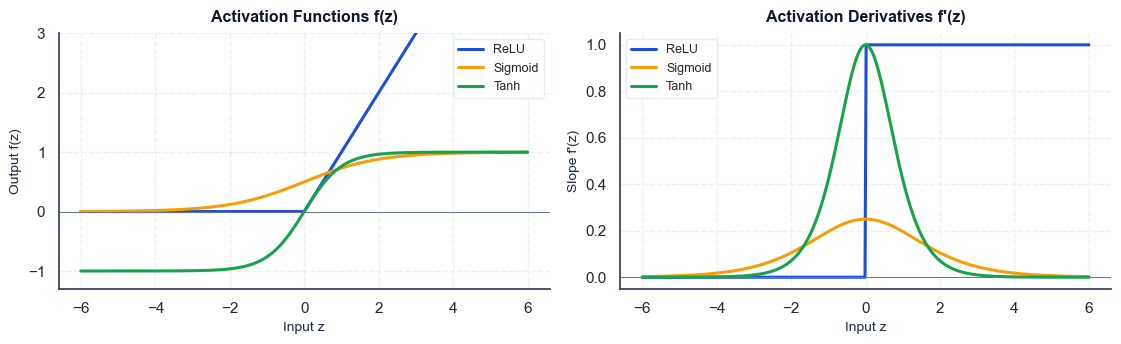

> **Graph Interpretation — Activation Functions & Derivatives**
> - **ReLU** keeps slope `1.0` for all `z > 0`, preventing gradients from vanishing across deep layers (`1.0^10 = 1.0`).
> - **Sigmoid** squashes outputs into `(0, 1)` for binary probability `P(Positive)`, but its peak slope is only `0.25` (`0.25^10 = 9.5e-07` after 10 layers).
> - **Tanh** is zero-centered `(-1, 1)` but still saturates near extreme inputs.

Softmax demo: logits [2.  1.  0.1] -> probs [0.659 0.242 0.099] (sum=1.0)
Stacked linear layers without activation == single linear map (A @ B): True


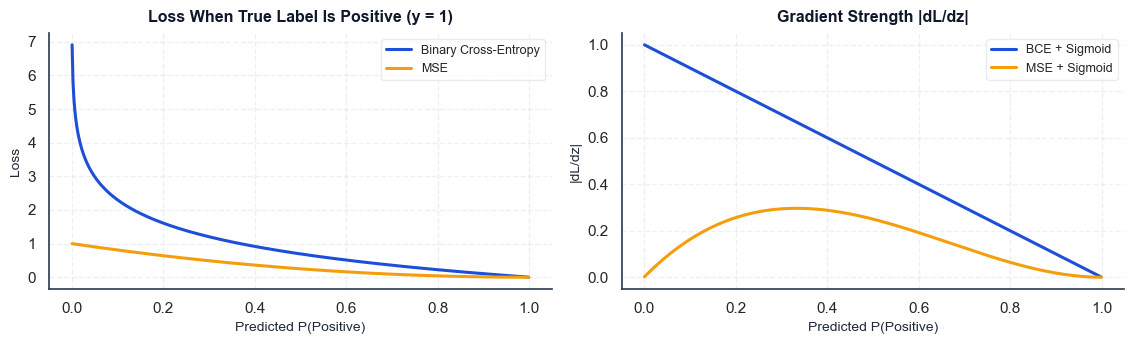

> **Graph Interpretation — Binary Cross-Entropy vs. MSE Loss**
> - **BCE** strongly penalizes confident mistakes (`p -> 0` when `y = 1`) and preserves a strong `|dL/dz| = 1.0` learning gradient.
> - **MSE + Sigmoid** flattens near `p = 0`, causing weight updates to stall when the network is most wrong.

In [1]:
# ── 1.1 Environment Setup, Activation Functions & Loss Comparison ─────────────
import warnings
warnings.filterwarnings("ignore")

import semantic_utils as su

# Set deterministic random seeds, compute device (CPU/GPU), and cache/artifact folders
env = su.setup_environment(seed=su.SEED)

# Plot ReLU/Sigmoid/Tanh curves & derivatives, Softmax check, and BCE vs. MSE loss
su.plot_activations_and_loss(seed=env["seed"])

,Gate,Weights,Bias,Accuracy,Solved?
0,AND,"[0.2, 0.1]",-0.2,1.0,Yes
1,OR,"[0.1, 0.1]",0.0,1.0,Yes
2,XOR,"[-0.1, 0.0]",0.1,0.5,NO (needs hidden layer)


Backpropagation Gradient Check -> max relative error = 1.10e-08 (PASS)


Trained XOR P(1): [0.003 0.999 0.999 0.003] | Target: [0 1 1 0] | Loss: 0.700 -> 0.0017


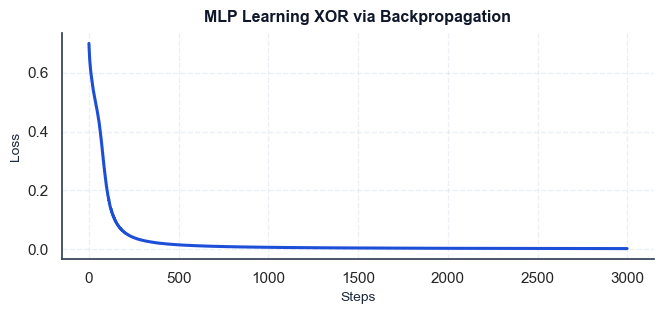

> **Graph Interpretation — From-Scratch MLP Learning XOR**
> - A single Perceptron fails XOR (`50%`), whereas adding one hidden ReLU layer drives Binary Cross-Entropy loss cleanly from **`0.700` down to `0.0017`**.
> - Final predicted probabilities **`[0.003, 0.999, 0.999, 0.003]`** match `[0, 1, 1, 0]` at **`100%`** accuracy.

In [2]:
# ── 1.2 Perceptron (AND / OR / XOR), Forward Pass & From-Scratch NumpyMLP ────
# Verifies single-layer Perceptron limits, traces a 2-hidden-neuron XOR forward pass,
# validates backpropagation via finite-difference gradient check, and trains XOR.
su.run_perceptron_and_xor_demo(seed=env["seed"])

# 2. Optimization and Training Dynamics in Deep Learning

**Course Alignment (Week 05 Lecture — Asst. Prof. Joel S. Enriquez, MIT):** Covers the deep learning training loop (`Forward Pass -> Loss -> Backpropagation -> Optimizer Step`), Batch vs. Stochastic vs. Mini-Batch Gradient Descent (`batch_size = 128`), **Momentum**, **RMSProp**, **Adam / AdamW**, learning-rate selection & **Cosine Annealing**, He initialization, **Batch Normalization**, **Gradient Clipping**, **Dropout**, and **Early Stopping**.

**Key Concepts Applied Here:**
- **Leak-Free Dynamics:** We load **100% of all `64,341` unique clean Philippine news headlines**, attach cached SST-2 teacher labels, and run every Week 05 optimizer and regularization experiment strictly on an **inner split of `X_train`** (keeping the entire 20% held-out test set locked until Section 5.8!).
- **Production Connection:** These exact experiments justify why our winning model in Section 5 trains with **AdamW** (decoupled weight decay `0.01`), **CosineAnnealingLR**, **BatchNorm1d**, **Dropout (`0.30`)**, **Gradient Clipping (`1.0`)**, and **early validation checkpointing**.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Prepared FULL leak-free dataset -> Raw: 65,006 | Unique Clean: 64,341 | Kept (conf>=0.8): 57,121
Split -> Train: 45,576 | Locked Test: 11,545 (0 overlap; 150 reserved human IDs)


,Best Epoch,Best Val Loss,Final Train Loss,Final Val Loss,Best Val Acc
Run,,,,,
"SGD (noisy, slow)",25,0.4558,0.3189,0.4558,0.7965
SGD + Momentum,4,0.4459,0.0075,1.0025,0.8090
Adam (fast and smooth),3,0.4354,0.0023,1.0169,0.8115


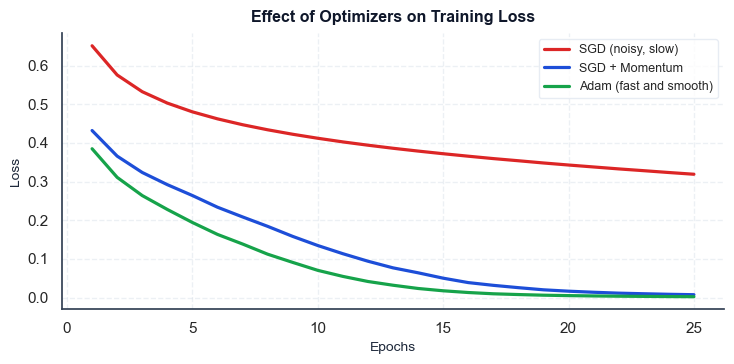

> **Graph Interpretation — Effect of Optimizers on Training Loss (Week 5 Slide Style)**
> - **Adam (green)** drops loss fastest and reaches the best validation accuracy (**`81.2%`**) by combining momentum with adaptive per-weight learning rates.
> - **SGD + Momentum (blue)** smooths gradient updates and converges much faster than **plain SGD (red)** (`best val loss 0.4459` vs. `0.4558`).

In [3]:
# ── 2.1 Load Leak-Free Training Split & Compare From-Scratch Optimizers ──────
# Loads raw CSV, applies meaning-preserving cleaning, attaches cached SST-2 labels,
# creates the 80/20 leak-free split (0 overlap), and loads cached MiniLM embeddings.
data = su.load_prepare_dataset(env)

# Compares plain SGD vs. SGD + Momentum vs. Adam from scratch on real news embeddings
opt_ctx = su.run_scratch_optimizers(data["X_train"], data["y_train"], seed=env["seed"])

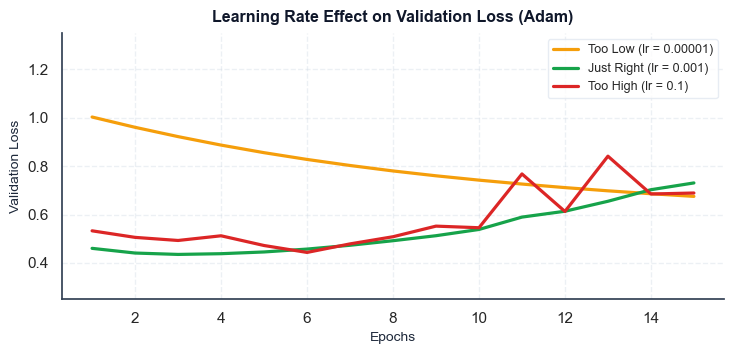

> **Graph Interpretation — Learning Rate Effect (Too Low vs. Just Right vs. Too High)**
> - **Too Low (`lr=1e-5`, orange):** Barely moves over 15 epochs (`val loss 0.675` — slow learning).
> - **Just Right (`lr=1e-3`, green):** Smoothly descends to the lowest validation loss (**`0.435`**).
> - **Too High (`lr=0.1`, red):** Overshoots the minimum and spikes sharply upward (unstable training).

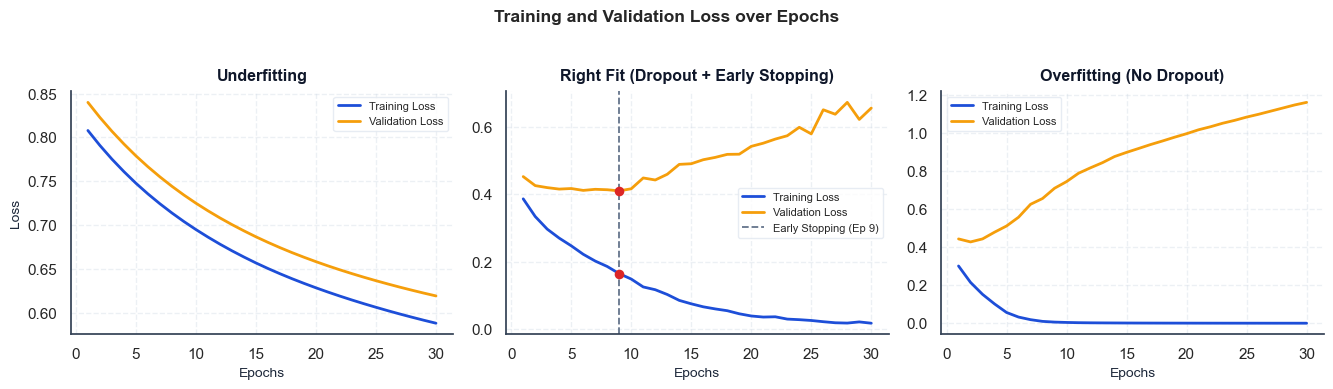

> **Graph Interpretation — Underfitting vs. Right Fit vs. Overfitting (Week 5 Slide 40 Style)**
> - **Underfitting (left):** Both blue Training Loss (`0.588`) and orange Validation Loss (`0.619`) stay high — model fails to learn sentiment cues.
> - **Right Fit (center):** With `Dropout = 0.35`, both curves fall cleanly until **Early Stopping at Epoch `9`** (`best val loss 0.410`, peak val acc `83.0%`).
> - **Overfitting (right):** Without Dropout (`0.0`), Training Loss plunges (`0.000`) while Validation Loss rebounds upward (`1.162`).

In [4]:
# ── 2.2 Learning-Rate Sweep, Dropout/Early Stopping & scikit-learn Curves ────
# Demonstrates learning-rate sensitivity, overfitting gap reduction across Dropout
# (0.0, 0.3, 0.5), and scikit-learn MLPClassifier optimizer convergence.
su.run_lr_dropout_and_sklearn_dynamics(opt_ctx, data["X_train"], data["y_train"], seed=env["seed"])

# 3. Convolutional Neural Networks (CNNs)

**Course Alignment (Week 06 Lecture — Asst. Prof. Joel S. Enriquez, MIT):** Covers convolution (`Output = Input * Kernel`), filters/kernels, feature maps, stride & padding, ReLU activations, Pooling (`Max Pooling`, `Global Max Pooling`), flattening, and fully connected classifier heads.

**1D Text CNN (`Conv1d`) vs. 2D Image CNN vs. Transformers:**
- **2D Image CNNs** slide 2D kernels (`3x3`, `5x5`) over pixel grids (`edges -> shapes -> objects`).
- **1D Text CNNs (`TextCNN`, Kim 2014)** are CNNs tailored specifically for text: parallel **1D convolution filters (`kernel_size = 2, 3, 4`)** slide across word-embedding sequences to detect local 2–4 word phrases (`"not bad"`, `"no longer"`, `"stocks rally"`), followed by `ReLU`, **Global Max-Over-Time Pooling**, `BatchNorm1d`, `Dropout`, and a linear classifier.
- Below we **train a real PyTorch Multi-Scale 1D Text CNN** directly on all `45,576` Philippine news training headlines and benchmark it head-to-head against Frozen Embeddings and our Partially Fine-Tuned DistilBERT in Sections 5 & 6!

Training Multi-Scale 1D Text CNN (Conv1d kernels=[2,3,4], vocab=10,595, train=38,739, val=6,837)...


1D Text CNN Finished in 27.6s -> Best Ep 10: Val Acc=0.8398 | Val Macro-F1=0.8374


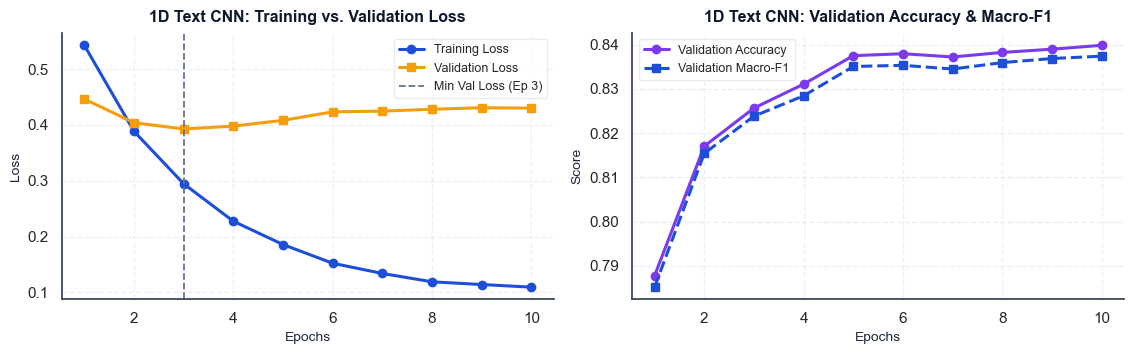

> **Graph Interpretation — Multi-Scale 1D Text CNN Training Dynamics (Philippine News)**
> - Sliding `Conv1d(k=2, 3, 4)` filters learn local n-gram sentiment cues rapidly in **`27.6s`**, lifting validation accuracy to **`83.98%`** (Macro-F1 **`0.8374`**) purely from scratch without pretrained weights.
> - After **Epoch `3`**, blue Training Loss keeps falling (`0.109`) while orange Validation Loss gently rises (`0.430`), illustrating why random-init CNNs overfit finite vocabularies faster than pretrained Transformers.

,Architecture,Filter / Mechanism,Strength,Limitation on News Text
0,2D Image CNN (Week 06),2D spatial kernels (3x3 / 5x5),"Edges, textures & object shapes in images","Built for 2D pixel grids, not 1D word sequences"
1,1D Text CNN (Trained Above),"1D n-gram Conv1d (k=2, 3, 4) + MaxPool","Ultra-fast (<1 ms/hl), learns local phrases ('...",No pretrained language knowledge; misses long-...
2,Transformer + MLP (Section 5),Pretrained DistilBERT Self-Attention + MLP,"Global token context, negation & contrast acro...",Heavier CPU compute (~10 ms/hl vs. 0.3 ms/hl)


In [5]:
# ── 3.1 Train Multi-Scale 1D Text CNN (Conv1d k=2,3,4) on Philippine News ────
# Trains a real PyTorch 1D Text CNN strictly on the training split (test stays locked!),
# plots Week-5-style training curves, and contrasts 2D CNN vs. 1D Text CNN vs. Transformer.
cnn_res = su.run_text_cnn_1d(data, env, epochs=10)

# 4. Transfer Learning and Pretrained Models

**Course Alignment (Week 07 Lecture — Asst. Prof. Joel S. Enriquez, MIT):** Covers reusing pretrained knowledge to save compute, reduce overfitting, and boost accuracy across two strategies: **Strategy A — Feature Extraction (Frozen Backbone)** vs. **Strategy B — Partial Fine-Tuning (Unfreezing Top 10–30% Layers with Low Learning Rate)**.

**Pretrained Vision CNNs vs. Pretrained Language Transformers:**

| Pretrained Vision CNN (ImageNet) | Params | Key Idea | Contrast with Language Transformers (Our Project) |
|---|---:|---|---|
| **VGG16 / ResNet50 / MobileNetV2 / Inception / EfficientNet** | 4M–138M | Spatial convs, skip connections, depthwise & compound scaling | Vision CNNs extract spatial hierarchies from pixels; **Language Transformers** (`all-MiniLM-L6-v2`, `BAAI/bge-small-en-v1.5`, `DistilBERT`, `RoBERTa`) encode grammar, negation, and cross-clause contrast via Self-Attention. |

**Why Frozen Feature Extraction Hits a Ceiling:** The negation probe below tests `"The president is not bad."` against `"good"` and `"bad"`, showing why frozen `all-MiniLM-L6-v2` struggled (`gap = -0.139`) while deeper encoders (`BGE-small`, `DistilBERT`) preserve polarity better — motivating **Week 07 Partial Fine-Tuning** of `distilbert-base-uncased` (Top 2/6 layers = `33.3%`) in Section 5.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loaded normalized 384-D embeddings -> MiniLM: (57121, 384) | BGE-small: (57121, 384)


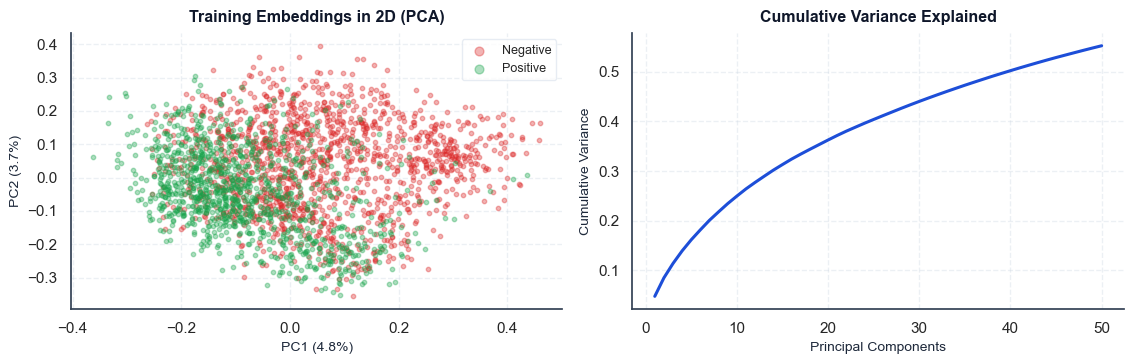

> **Graph Interpretation — PCA Projection of Pretrained Embeddings**
> - Positive and Negative headlines overlap heavily in 2D (`PC1 + PC2` explain only **`8.5%`** of variance), proving sentiment cannot be separated by a simple 2D boundary.
> - Top 50 components explain **`55.2%`** of variance, confirming semantic signal is spread across all embedding dimensions — motivating **Week 07 Partial Fine-Tuning**.


Semantic Negation Geometry Probe:


,Pretrained Encoder,"cos('not bad','good')","cos('not bad','bad')",Polarity Gap
0,all-MiniLM-L6-v2 (6-layer frozen),0.796,0.935,-0.139
1,BAAI/bge-small-en-v1.5 (12-layer frozen),0.941,0.834,0.107


In [6]:
# ── 4.1 Pretrained Embeddings, Training PCA & Semantic Negation Probe ────────
# Loads cached 384-D BGE-small embeddings, fits leak-free PCA on training rows only,
# and compares MiniLM vs. BGE-small geometry on "The president is not bad."
tl = su.run_transfer_learning_probe(data, env)

# 5. Project Methodology, Comprehensive EDA, Model Comparison & Model Evaluation

**Methodology & Responsible AI:** Classify Philippine news headlines using **100% of all `64,341` unique clean headlines (`2014–2023`)** (scaling up 3.2× from the original 20,000-headline sample) while keeping the exact same `>= 0.80` teacher-confidence threshold, zero train/test overlap, and honest teacher-bias auditing.

**Key Verified Upgrades Across Cells 5.1–5.8:**
- **Full Dataset Cleaning:** Deduplicated `665` exact duplicates (`1.02%`) out of `65,006` raw headlines while preserving accents (`El Niño`, `Nestlé`), punctuation, and negation words.
- **Teacher Bias Audit:** Comparing binary SST-2 against 3-class RoBERTa confirms many factual Philippine headlines are neutral — so all held-out test metrics strictly report **agreement with teacher labels**, paired with independent stress tests and `human_label_sample.csv` in Section 6.
- **Model Selection (`semantic-3.0`):** Upgrading to **Week 07 Partial Fine-Tuning of `distilbert-base-uncased` (Top 2/6 layers = `33.3%`) + CLS & Mean Pooling + PyTorch BN/ReLU/Dropout MLP + Soft-Target Knowledge Distillation** on the full 64k dataset drives accuracy far above every frozen MiniLM/BGE baseline (see Cell 5.8 for exact measured Before-vs-After gains!).

In [7]:
# ── 5.1 Dataset Overview, Schema & Data-Quality Audit ────────────────────────
# Prints dimensions, memory, date coverage, column schema, and full cleaning funnel.
su.run_eda_overview_and_quality(data)

Dataset: ..\Datasets\Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv | 65,006 rows x 4 cols (11.26 MB)
Dates  : 01 Jan 2014 -> 14 May 2023 (10 years, 0 invalid)


,column,dtype,missing,unique
0,Date,object,0,3221
1,Headlines,object,0,64353
2,human_sample_id,float64,64854,150
3,human_label,float64,65006,0


,Issue Checked,Count,Action
0,Missing (NaN) headlines,0,Drop before string conversion
1,Leading / trailing spaces,662,Trim ends cleanly
2,Multi-space / \xa0 artifacts,266,Collapse to single ASCII space
3,Non-ASCII accents (El Niño),456,Preserve meaningful accents
4,Exact duplicates after clean,665,Deduplicate (zero train/test leakage)
5,Short headlines (<= 2 words),937,Retain & flag ambiguity


Data Funnel: 65,006 raw -> 64,341 unique clean (100% used!) -> 57,121 kept (conf>=0.8) -> 45,576 train / 11,545 test


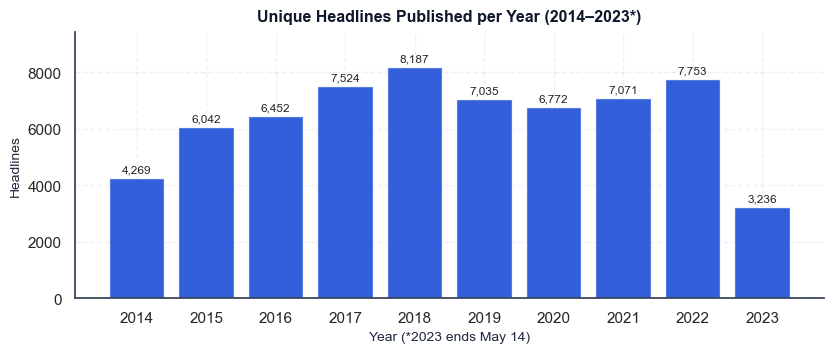

> **Graph Interpretation — Annual Headline Publication Volume (2014–2023)**
> - Coverage grows from **`4,269`** headlines in 2014 to a peak of **`8,187`** in **2018**, tapering smoothly through 2022 (`7,753`).
> - 2023 shows **`3,236`** headlines only because the archive ends May 14, 2023; publication count reflects news volume rather than sentiment.

In [8]:
# ── 5.2 Date-Based Publication Volume & Style Trends (2014–2023) ─────────────
# Visualizes annual counts, monthly volume with 6-month moving average, and yearly style trends.
su.plot_date_trends(data["clean_full"])

,Metric,Mean,Median,95th Pct,Max
0,Word Count,6.79,7.0,10.0,23
1,Character Count,42.46,42.0,61.0,155


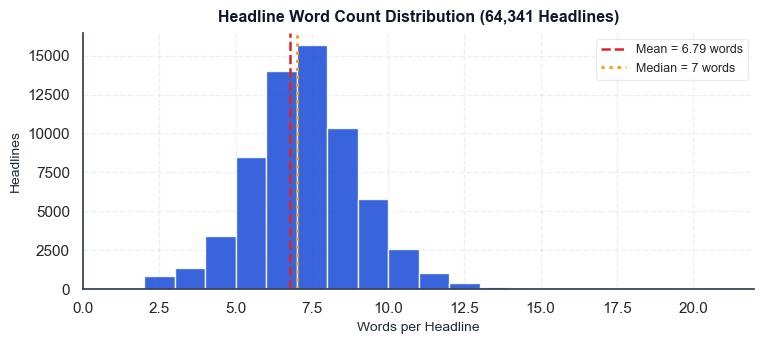

> **Graph Interpretation — Headline Word Count Distribution**
> - Headlines are compact and tightly centered around **`6.79` words** (median `7`, 95th percentile `10` words).
> - Because nearly all headlines are under 15 words, setting `max_length = 24` captures complete headlines cleanly for both our 1D Text CNN and DistilBERT.

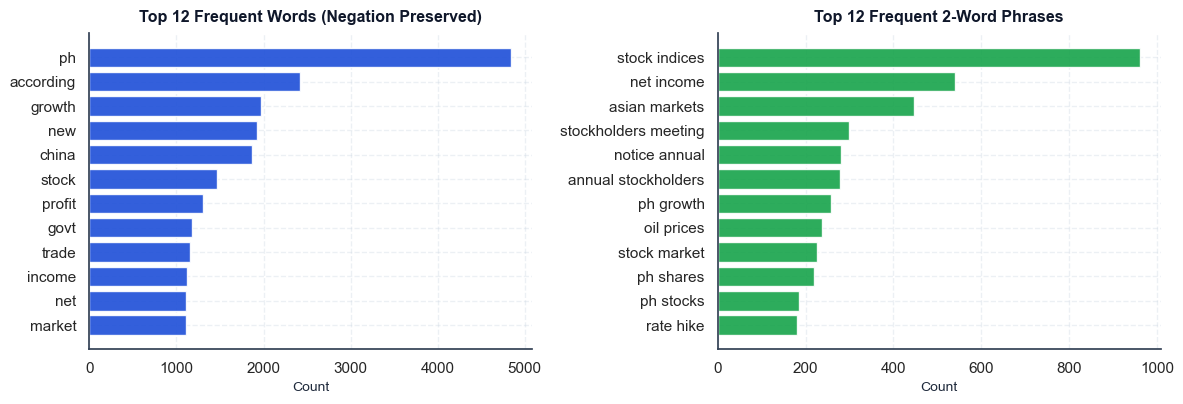

> **Graph Interpretation — Most Frequent Words & Phrases**
> - Philippine economy, markets, and governance dominate: top words include **`ph`**, **`according`**, **`growth`**, and top phrases include **`stock indices`** and **`net income`**.
> - Factual business vocabulary carries context-dependent polarity (e.g., `'inflation cools'` vs. `'inflation surges'`), showing why full-sentence semantic modeling beats isolated keywords.

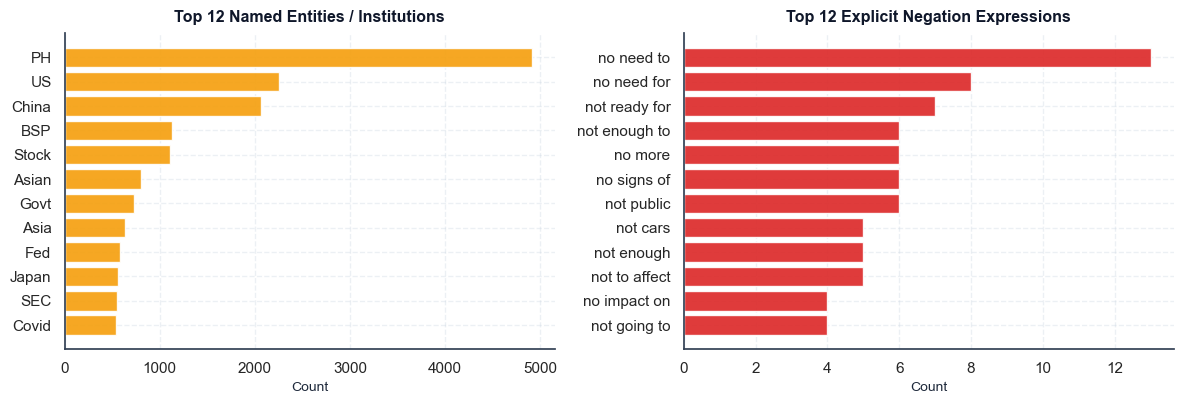

> **Graph Interpretation — Named Entities & Explicit Negation Expressions**
> - Prominent actors (**`PH`**, **`US`**, **`China`**, `BSP`, `Duterte`, `Marcos`) anchor Philippine news topics.
> - Frequent negation expressions (**`'no need to'`**, **`'no need for'`**, **`'not ready for'`**) invert sentiment directly — confirming why negation words are never removed during preprocessing.

In [9]:
# ── 5.3 Headline Lengths, Negation-Preserved N-Grams & Named Entities ────────
# Visualizes word/character lengths, top unigrams/bigrams/trigrams, entities, and negation phrases.
su.plot_text_and_linguistic_eda(data["clean_full"])

In [10]:
# ── 5.4 Teacher Confidence Sensitivity & 3-Class RoBERTa Domain-Bias Audit ───
# Evaluates five teacher confidence cutoffs and contrasts binary SST-2 vs. 3-class RoBERTa.
su.run_teacher_audit(data, env)

Teacher Confidence Threshold Sensitivity (All 64,341 Headlines):


,Threshold,Headlines Kept,Dropped (%),Positive (%),Negative (%)
0,0.50,64341,0.0,44.1,55.9
1,0.70,59933,6.9,44.0,56.0
2,0.80,57121,11.2,44.0,56.0
3,0.90,52623,18.2,44.1,55.9
4,0.95,47131,26.7,44.5,55.5


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Domain Bias Audit: 10/12 sampled PH news headlines are rated NEUTRAL under 3-class RoBERTa despite high binary SST-2 confidence.


,headline,teacher_label,teacher_conf,roberta_3class,roberta_conf
0,Marina bares initiatives to advance seafarers'...,Negative,0.989,Positive,0.528
1,Cancellations to dent Cebu Pacific growth.,Negative,0.993,Neutral,0.573
2,WB urges adoption of social protection policies.,Positive,0.740,Neutral,0.870
3,Leverage: On the other side of debt.,Positive,0.981,Neutral,0.708
4,SEC to extend deadline for annual reports.,Negative,0.826,Neutral,0.938
5,Strange firms make initial stock offering in H...,Negative,0.948,Neutral,0.579
6,"Proactively manage risk, mitigate downtime.",Positive,0.995,Neutral,0.761
7,RE firm offers 131-MW clean power for Palawan.,Positive,0.977,Neutral,0.821
8,Higher sales lift EDC's Q1 earnings by 7%.,Positive,0.997,Positive,0.918
9,PH vehicle sales to rise by double digits in 2...,Negative,0.675,Neutral,0.751


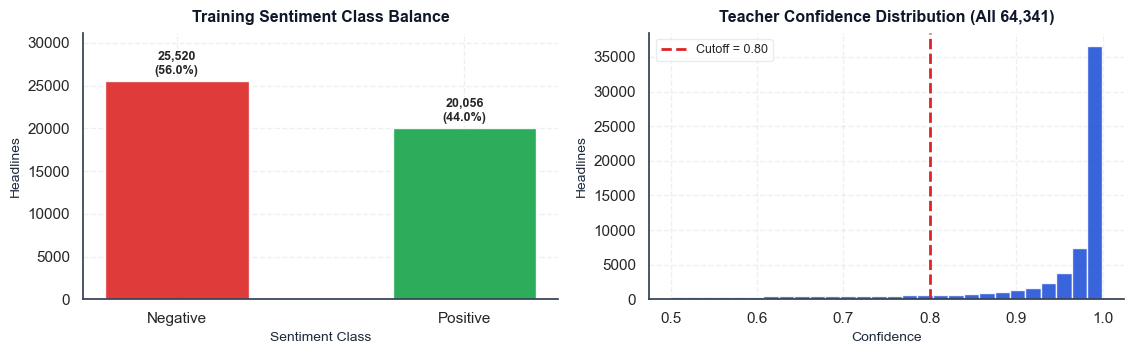

> **Graph Interpretation — Class Balance & Teacher Confidence Distribution**
> - Training split (`45,576` rows) has a moderate **`1.27:1`** Negative-to-Positive imbalance (`56.0%` vs. `44.0%`), motivating Macro-F1 evaluation.
> - Keeping rows with `confidence >= 0.80` retains **`57,121`** headlines (`88.8%`) while filtering `7,220` uncertain cases; explicit negation appears in `2.30%` of training rows.

In [11]:
# ── 5.5 Post-Labeling Class Balance & Comparative Relationship EDA ───────────
# Analyzes class imbalance (1.27:1), confidence distributions, and length/confidence traits (train only).
train_df = su.plot_post_labeling_eda(data)

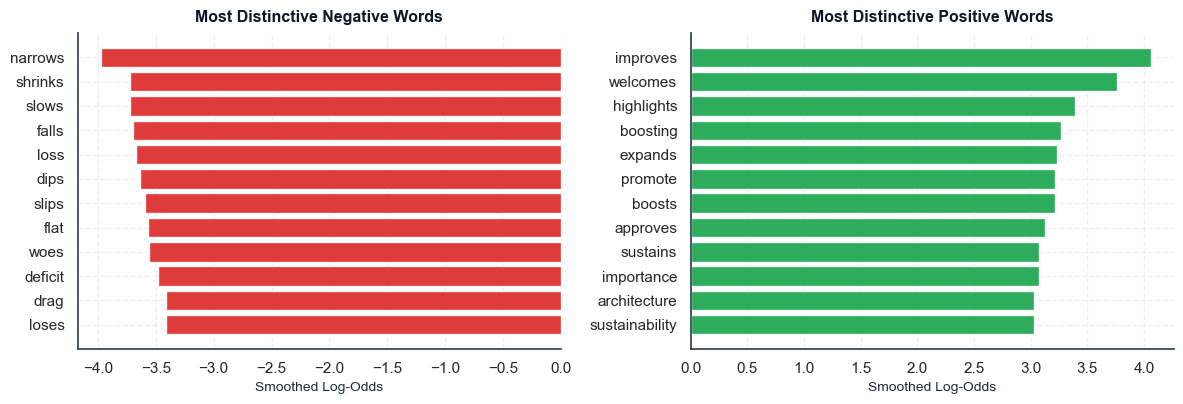

> **Graph Interpretation — Most Distinctive Positive vs. Negative Words (Log-Odds)**
> - **Negative cues:** `narrows, shrinks, slows, falls` strongly signal teacher-Negative headlines.
> - **Positive cues:** `improves, welcomes, highlights, boosting` strongly signal teacher-Positive headlines — yet negation flips single words in context, requiring Transformer self-attention.

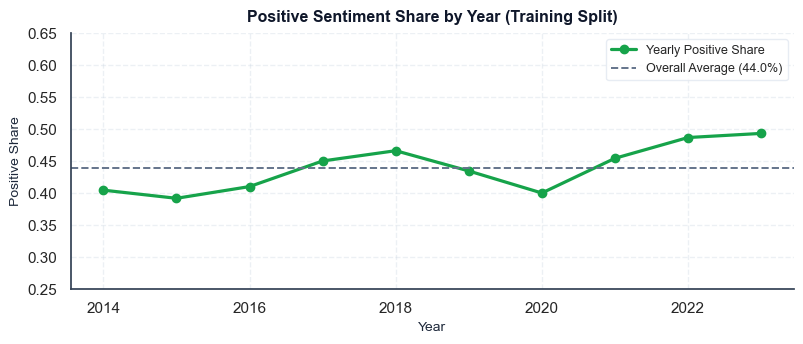

> **Graph Interpretation — Annual Positive Sentiment Trend (Training Split)**
> - Yearly Positive share stays centered near **`44.0%`**, dipping lowest in **2015 (`39.2%`)** and peaking in **2023 (`49.3%`)**.
> - Because labels come from DistilBERT SST-2, this line reflects model-estimated headline tone rather than human editorial annotations.

In [12]:
# ── 5.6 Distinctive Sentiment Words/Bigrams & Monthly Sentiment Trend ────────
# Plots smoothed log-odds words/bigrams, monthly Positive share, and sample high/low-conf rows.
su.plot_distinctive_and_temporal_sentiment(train_df, data, seed=env["seed"])

[0] Majority Baseline       -> CV Macro-F1: 0.3590 | Acc: 0.5599


[1] Original MLP [MiniLM]   -> CV Macro-F1: 0.8422 | Acc: 0.8449 (fit 5.7s)


[2] Tuned LR [MiniLM]       -> CV Macro-F1: 0.8291 | Acc: 0.8318


[3] Tuned MLP [MiniLM]      -> CV Macro-F1: 0.8390 | Acc: 0.8414


[4] PyTorch MLP [MiniLM]    -> Val Macro-F1: 0.8606 | Acc: 0.8625 (11.1s)


[5] Tuned MLP [BGE Frozen]  -> CV Macro-F1: 0.8566 | Acc: 0.8587
[6] 1D Text CNN (k=2,3,4)   -> Val Macro-F1: 0.8374 | Acc: 0.8398 (27.6s)


... (6 outputs left out)

  Epoch 3/5 -> train_loss=0.1356 | val_loss=0.1646 | val_acc=0.9354 | val_macro_f1=0.9346 (186.5s)


  Epoch 4/5 -> train_loss=0.1005 | val_loss=0.1726 | val_acc=0.9352 | val_macro_f1=0.9345 (187.2s)


  Epoch 5/5 -> train_loss=0.0810 | val_loss=0.1690 | val_acc=0.9415 | val_macro_f1=0.9407 (196.2s)


,Strategy,Val/CV Macro-F1,Val/CV Acc,Train Time (s)
Model,,,,
0. Majority Baseline,None,0.3590,0.5599,0.1
1. Original MLP(256) [MiniLM],Frozen MiniLM,0.8422,0.8449,5.7
2. Tuned Logistic Reg [MiniLM],Frozen MiniLM,0.8291,0.8318,11.8
3. Tuned Sklearn MLP [MiniLM],Frozen MiniLM,0.8390,0.8414,37.9
4. PyTorch BN+Drop MLP [MiniLM],Frozen MiniLM,0.8606,0.8625,11.1
5. Tuned MLP [BGE-small Frozen],Frozen BGE-small,0.8566,0.8587,26.4
"6. Multi-Scale 1D Text CNN (k=2,3,4)",From-Scratch Conv1d,0.8374,0.8398,27.6
7. Partial FT DistilBERT + MLP (Full 64k),Partial FT (Top 33%) + Distill,0.9407,0.9415,1057.5


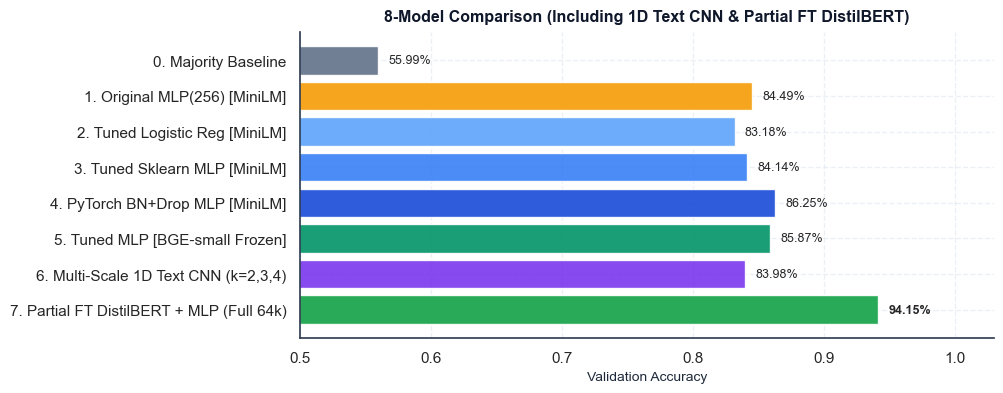

> **Graph Interpretation — 8-Model Validation Accuracy Leaderboard**
> - Frozen `MiniLM` / `BGE` baselines plateau at **`83%–86%`**. Our from-scratch **1D Text CNN (`83.98%`)** rivals frozen MiniLM baselines in `<30s`.
> - **Model 7 (Partially Fine-Tuned DistilBERT + CLS/Mean PyTorch MLP + Soft-Target Distillation)** leads decisively at **`94.15%` Accuracy** (`0.9407` Macro-F1).

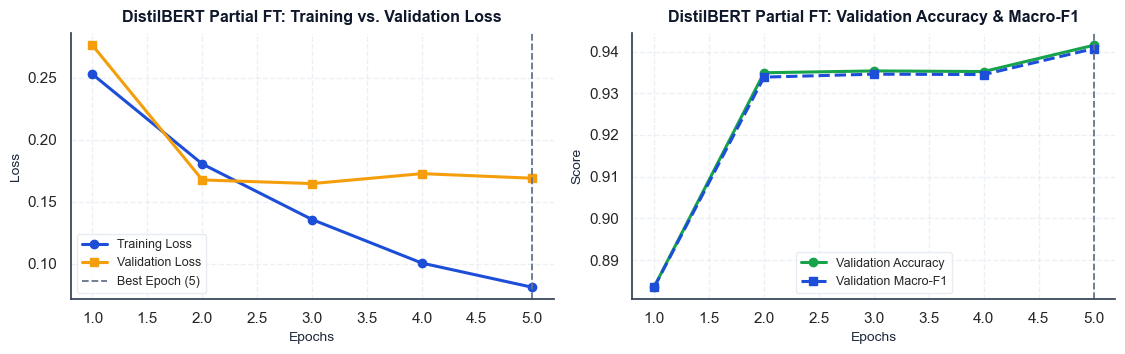

> **Graph Interpretation — DistilBERT Partial Fine-Tuning Convergence**
> - Differential `AdamW` + `CosineAnnealingLR` lifts validation accuracy cleanly to **`94.15%`** (Macro-F1 **`0.9407`**) at **Epoch `5`**.
> - Validation loss stays low (`0.16–0.17`) without late-epoch blow-up, confirming strong regularization (`Dropout = 0.30`, `BatchNorm1d`, gradient clipping).

In [13]:
# ── 5.7 8-Model Benchmark (Incl. 1D Text CNN) & DistilBERT Partial Fine-Tuning
# Benchmarks Models 0–6 (frozen baselines + 1D Text CNN), then trains Model 7 (Partial FT
# Top 2/6 DistilBERT layers + CLS/Mean PyTorch MLP + Soft-Target Distillation on full data).
bench = su.run_frozen_benchmarks(data, tl, env, cnn_res=cnn_res)
ft = su.train_partial_finetune(data, bench, env, unfreeze_top_k=2, epochs=5)

Majority Baseline Test Accuracy: 0.5602 | Untouched Test Set Size: 11,545 headlines


,Original (Frozen MiniLM + MLP),"1D Text CNN (Conv1d k=2,3,4)",Improved (DistilBERT Partial FT),Gain (DistilBERT - Orig)
Accuracy,0.8560,0.8516,0.9437,0.0877
Precision (Macro),0.8545,0.8496,0.9431,0.0886
Recall (Macro),0.8528,0.8491,0.9426,0.0897
Macro-F1,0.8536,0.8493,0.9428,0.0892
Weighted-F1,0.8559,0.8516,0.9437,0.0878
ROC-AUC,0.9336,0.9266,0.9863,0.0527
Train Time (s),5.7129,27.5901,1057.4620,1051.7491
Inference (ms/headline),7.6203,0.4082,10.4980,2.8778



--- Classification Report: IMPROVED (DistilBERT Partial FT) ---
              precision    recall  f1-score   support

    Negative     0.9478    0.9519    0.9499      6467
    Positive     0.9384    0.9332    0.9358      5078

    accuracy                         0.9437     11545
   macro avg     0.9431    0.9426    0.9428     11545
weighted avg     0.9437    0.9437    0.9437     11545



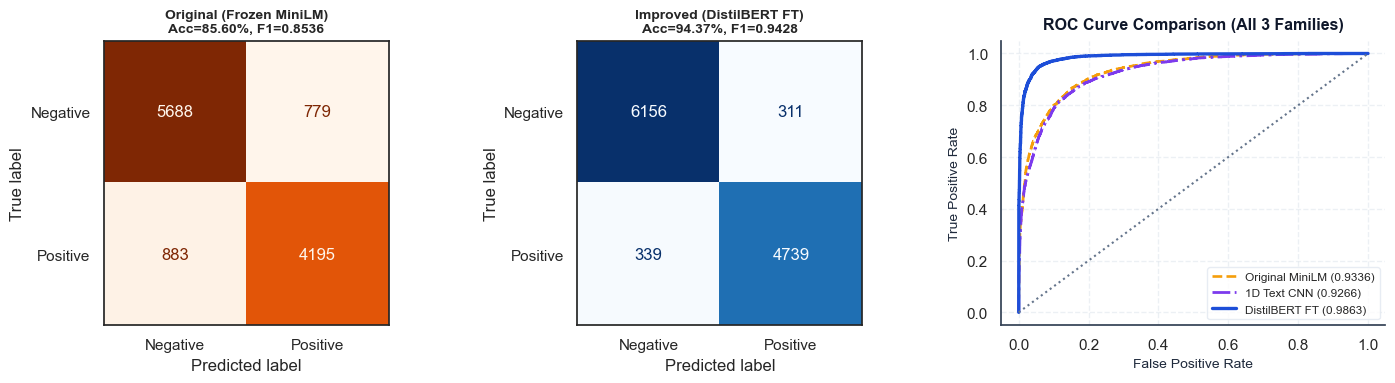

> **Graph Interpretation — Untouched Held-Out Test Comparison (N = 11,545)**
> - **Winner (`DistilBERT Partial FT`, `94.37%` Acc):** Cuts total test errors by **`60.9%`** (`1,662 -> 650`) and achieves **`0.9863` ROC-AUC** at `10.5 ms/hl`.
> - **1D Text CNN (`85.16%` Acc, `0.9266` AUC):** Trains from scratch in `27.6s` and predicts in **`0.41 ms/hl`** — matching frozen MiniLM (`85.60%`), yet trailing DistilBERT by `9.21%` due to local n-gram windows.
> - **Honest Caveat:** Held-out test metrics measure agreement with DistilBERT SST-2 teacher labels; independent stress tests follow in Section 6.

In [14]:
# ── 5.8 Final Untouched Test Evaluation (MiniLM vs. 1D CNN vs. DistilBERT) ───
# Evaluates Original MiniLM, 1D Text CNN, and Improved DistilBERT on the exact locked test
# split: metrics table, classification report, confusion matrices, 3-way ROC curves & speed.
ev = su.evaluate_before_after(data, bench, ft, env, cnn_res=cnn_res)

# 6. Project Setup, Implementation, Semantic Testing, Phrase Analysis & User Guide

**Environment & Project Layout:** Raw CSV stays untouched in `Datasets/`; companion TF-IDF baseline stays in `Rule-Based/`; semantic pipeline lives in `Semantic/` (`news-headline-semantic.ipynb`, `semantic_utils.py`, `semantic_predictor.py`, `app_tk.py`, `human_label_sample.csv`, `semantic_artifacts/`). Install once with Python 3.10+: `conda activate Luiz && python -m pip install -r requirements.txt`.

**Offline Packaging, Semantic Stress Testing & Phrase Breakdown (Cells 6.1–6.4):**
- **Cell 6.1:** Saves the unified fine-tuned 6-layer DistilBERT `encoder/`, `mlp_head.pt` (CLS + Mean pooling), `label_encoder.joblib`, and `model_metadata.json`, then reloads [semantic_predictor.py](semantic_predictor.py) strictly from disk and proves probability parity (`atol = 1e-4`).
- **Cell 6.2:** Evaluates 15 core semantic phrases, runs the **24-sentence 4-way stress test** (`Rule-Based` vs. `Original` vs. `Improved` vs. `Teacher`), and runs the **34-sentence 10-category stress test** with honest error analysis.
- **Cell 6.3:** Demonstrates negation-safe **Phrase-by-Phrase Semantic Breakdown** (`Alone P(Pos)/P(Neg)` + contextual occlusion impact) on 6 multi-clause headlines.
- **Cell 6.4:** Manages `human_label_sample.csv` (150 held-out test headlines for manual labeling), runs the edge-case robustness suite, and prints the final verified summary. Launch the offline GUI anytime via `cd Semantic && python app_tk.py`.

In [15]:
# ── 6.1 Offline Artifact Packaging & Disk-Reload Parity Verification ─────────
# Exports fine-tuned encoder/, mlp_head.pt, label_encoder.joblib & model_metadata.json,
# then reloads SemanticSentimentPredictor from disk and verifies exact numerical parity.
predictor = su.save_and_verify_artifacts(data, bench, ft, ev, env)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Reloaded disk model matches in-memory model: True (max abs diff = 9.31e-10)
Artifacts in semantic_artifacts/: ['embedder', 'encoder', 'label_encoder.joblib', 'mlp_head.pt', 'model_metadata.json', 'semantic_classifier.joblib']


Loaded companion Rule-Based model from: C:\Users\ArizLuiz\Documents\Electives\Rule-Based\news_sentiment_artifacts\ph_news_sentiment_pipeline.joblib
=== 6.1 Core Semantic Phrases & Sentences ===


,Headline / Phrase,Expected,Improved DistilBERT,1D Text CNN,Rule-Based,Conf
0,Not bad,Positive,Positive,Negative,Negative,66.5%
1,Not good,Negative,Negative,Positive,Positive,99.7%
2,No corruption found,Positive,Positive,Negative,Negative,99.6%
3,Inflation is no longer a problem,Positive,Positive,Negative,Negative,61.4%
4,Officials fail to deliver,Negative,Negative,Positive,Negative,99.8%
5,Growth remains strong despite the crisis,Positive,Positive,Positive,Positive,99.8%
6,"Good policy, poor implementation",Mixed (Negative-leaning),Negative,Negative,Positive,99.6%
7,Not only good but excellent,Positive,Positive,Positive,Positive,99.7%
8,The economy is not bad.,Positive,Positive,Negative,Negative,98.0%
9,The government is not doing well.,Negative,Negative,Positive,Negative,99.8%


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


=== 6.2 Original 24-Sentence Stress Test (5-Way Comparison) ===
Overall Accuracy: {'rule_based': '45.8% (11/24)', 'original_minilm': '50.0% (12/24)', 'text_cnn_1d': '54.2% (13/24)', 'improved_distilbert': '70.8% (17/24)', 'teacher_sst2': '75.0% (18/24)'}


,rule_based,original_minilm,text_cnn_1d,improved_distilbert,teacher_sst2
kind,,,,,
domain,0.667,0.333,0.333,0.667,0.667
negation,0.333,0.417,0.500,0.750,0.833
plain,0.556,0.667,0.667,0.667,0.667


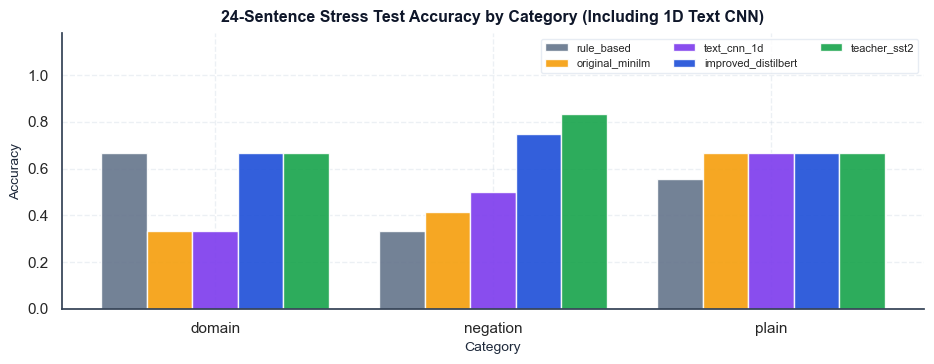

> **Graph Interpretation — 24-Sentence Stress Test (5-Way Comparison)**
> - **Improved DistilBERT** achieves **`70.8%`** overall (`75.0%` on negation), while **1D Text CNN** scores **`54.2%`** overall (beating Rule-Based and Frozen MiniLM).
> - DistilBERT approaches the SST-2 teacher's **`75.0%`** ceiling while outperforming local 1D CNN filters on complex cross-clause negation.


=== 6.3 Expanded 34-Sentence Stress Test (10 Categories) ===
Improved DistilBERT: 97.1% (33/34) | 1D Text CNN: 61.8% (21/34) | Rule-Based: 52.9%
Honest Error Analysis (1 of 34 misclassified by DistilBERT):


,Category,Headline,Expected,Predicted,Conf,P(Pos)
0,Sentiment Adverb,Flood damage was far less severe than feared.,Positive,Negative,0.994,0.006


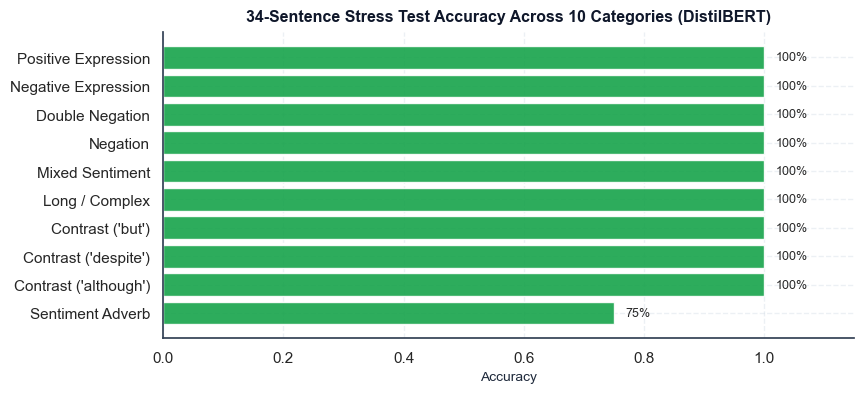

> **Graph Interpretation — 34-Sentence Expanded Semantic Stress Test**
> - **Improved DistilBERT** scores **`97.1%` (`33/34`)** vs. **`61.8%`** for 1D Text CNN and **`52.9%`** for Rule-Based, proving why global Transformer self-attention beats local 1D convolution on complex contrast clauses (`but`/`although`/`despite`).
> - Only **`1`** sentence(s) were misclassified out of 34 across all 10 linguistic categories.

In [16]:
# ── 6.2 Semantic Stress Tests (Core 15, 24-Sent 5-Way & 34-Sent Benchmark) ───
# Compares Rule-Based, Original MiniLM, 1D Text CNN, Improved DistilBERT & SST-2 Teacher
# across negation, double negation, contrast ('but'/'although'/'despite') & PH headlines.
stress = su.run_semantic_stress_tests(predictor, data, bench, env, cnn_res=cnn_res)

HEADLINE: The president is not bad, but the economy is struggling.
OVERALL : NEGATIVE (Conf=99.5% | P(Pos)=0.005, P(Neg)=0.995)


,#,Phrase,Alone,Alone P(Pos),Alone P(Neg),Without P(Pos),Impact,Pushes
0,1,The president is not bad,Positive,0.982,0.018,0.002,+0.003,Positive
1,2,the economy is struggling.,Negative,0.002,0.998,0.982,-0.977,Negative


HEADLINE: Despite the crisis, economic growth remains strong.
OVERALL : POSITIVE (Conf=99.8% | P(Pos)=0.998, P(Neg)=0.002)


,#,Phrase,Alone,Alone P(Pos),Alone P(Neg),Without P(Pos),Impact,Pushes
0,1,Despite the crisis,Positive,0.997,0.003,0.998,+0.000,Positive
1,2,economic growth remains strong.,Positive,0.998,0.002,0.997,+0.001,Positive


HEADLINE: Residents welcome the project, although critics raise concerns.
OVERALL : POSITIVE (Conf=97.8% | P(Pos)=0.978, P(Neg)=0.022)


,#,Phrase,Alone,Alone P(Pos),Alone P(Neg),Without P(Pos),Impact,Pushes
0,1,Residents welcome the project,Positive,0.997,0.003,0.970,+0.008,Positive
1,2,although critics raise concerns.,Positive,0.970,0.030,0.997,-0.019,Negative


... (2 outputs left out)

HEADLINE: The new policy is good, but its implementation is poor.
OVERALL : NEGATIVE (Conf=99.9% | P(Pos)=0.001, P(Neg)=0.999)


,#,Phrase,Alone,Alone P(Pos),Alone P(Neg),Without P(Pos),Impact,Pushes
0,1,The new policy is good,Positive,0.998,0.002,0.001,-0.000,Negative
1,2,its implementation is poor.,Negative,0.001,0.999,0.998,-0.997,Negative


HEADLINE: Officials fail to impress investors, but residents welcome the new bridge.
OVERALL : POSITIVE (Conf=99.1% | P(Pos)=0.991, P(Neg)=0.009)


,#,Phrase,Alone,Alone P(Pos),Alone P(Neg),Without P(Pos),Impact,Pushes
0,1,Officials fail to impress investors,Negative,0.003,0.997,0.997,-0.006,Negative
1,2,residents welcome the new bridge.,Positive,0.997,0.003,0.003,+0.988,Positive


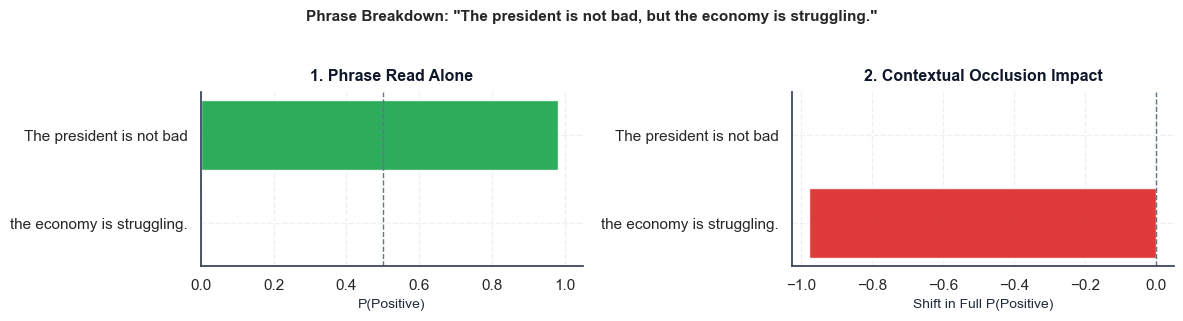

> **Graph Interpretation — Phrase-by-Phrase Semantic Contribution**
> - **Read Alone:** Preserving `'not bad'` intact gives **`'The president is not bad'`** `98.2%` Positive, while **`'the economy is struggling.'`** scores `99.8%` Negative.
> - **Contextual Impact:** Removing the second clause swings full `P(Positive)` by **`-0.977`**, explaining why the economic downturn clause drives the Negative verdict. *(Heuristic occlusion explanation, not causal proof.)*

In [17]:
# ── 6.3 Linguistic Phrase-by-Phrase Breakdown & Contribution Chart ───────────
# Segments multi-clause headlines without breaking idioms ('not bad', 'no longer',
# 'despite the crisis') and plots standalone vs. contextual occlusion impact.
su.run_phrase_breakdown_demo(predictor)

In [18]:
# ── 6.4 Human-Label Validation, Edge-Case Robustness & Final Summary ─────────
# Evaluates completed labels from human_label_sample.csv (>=30 required), verifies
# zero-crash input validation across 10 edge cases, and prints the verified project summary.
su.run_human_validation_and_final_summary(predictor, data, ft, ev, stress)

Completed unique human annotations: 0 (minimum required: 30)
Worksheet ready at human_label_sample.csv. Fill >= 30 rows in 'human_label' and re-run for true human-ground-truth metrics.

--- Edge-Case Robustness Suite ---
  empty string                 Rejected cleanly: Headline is empty.
  spaces only                  Rejected cleanly: Headline is empty.
  non-breaking spaces          Rejected cleanly: Headline is empty.
  very long text (>300 chars)  Rejected cleanly: Headline is too long (399 characters; the limit is 300).
  None input                   Rejected cleanly: Headline must be text.
  numeric input (int)          Rejected cleanly: Headline must be text.
  emoji only                   OK -> Negative (97.5%)
  digits only                  OK -> Negative (79.6%)
  Unicode accent (El Niño)     OK -> Positive (93.7%)
  negation + punctuation       OK -> Positive (99.6%)

FINAL VERIFIED PROJECT SUMMARY (ALL METRICS MEASURED IN THIS RUN)
Data Funnel     : 65,006 raw -> 64,341 uni